Epoch    0 | loss = 804.0775146484
Epoch  200 | loss = 0.2122354507
Epoch  400 | loss = 0.0989795923
Epoch  600 | loss = 0.0491346233
Epoch  800 | loss = 0.0245899465
Epoch 1000 | loss = 0.0124776419
Epoch 1200 | loss = 0.0064271842
Epoch 1400 | loss = 0.0034178952
Epoch 1600 | loss = 0.0019127104
Epoch 1800 | loss = 0.0011359075
Epoch 2000 | loss = 0.0007140820
Epoch 2200 | loss = 0.0004718616
Epoch 2400 | loss = 0.0003253310

Coeficientes:
[ 4.8949718e-03  7.3238301e-01  2.2620857e-03  2.5111222e-01
 -1.3324618e-03  3.2915920e-04  3.9701164e-04]


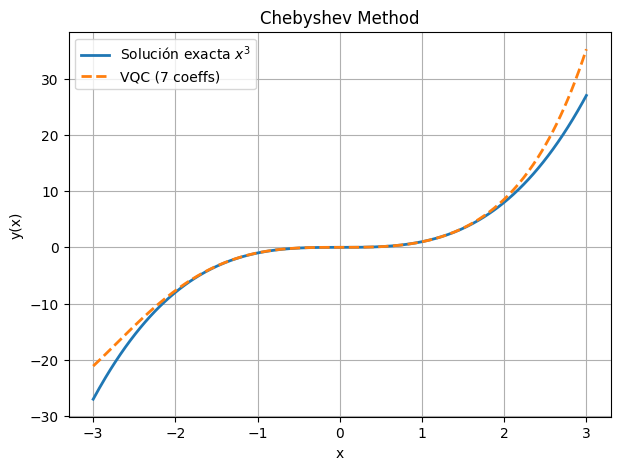

In [9]:
# ============================================================
# Integration using  Chebyshev polynomial coefficients
# ============================================================

import jax
import jax.numpy as jnp
import optax
import pennylane as qml
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# Parametros 
# ============================================================
n_qubits = 3          #Numero de qubits en el circuto Variacional
n_layers = 4          #Numero de Layers del circuito variacional
K_basis = 7           #Numero de términos en la expansion de Chebyshev
M_collocation = 50    #Numero de puntos de colacion de Chebyshev-Gauss-Lobatto
learning_rate = 0.01  #Tasa de aprendizaje del entrenamiento 
epochs = 2500         #Numero total de epocas del entrenamiento
lambda_bc = 10        #Peso de la penalizacion de la condicion de frontera
lambda_reg = 1e-4     #Regularizacion L2 
seed = 42


dev = qml.device("default.qubit", wires=n_qubits)

# Evalua los polinomios de Chebyshev T0(x),...,T_{K-1}(x)
def chebyshev_polynomials_single(x, K):
    vals = [1.0]
    if K == 1:
        return jnp.array(vals)
    vals.append(x)
    T0, T1 = 1.0, x
    for k in range(2, K):
        Tk = 2.0 * x * T1 - T0
        vals.append(Tk)
        T0, T1 = T1, Tk
    return jnp.array(vals)

# Construye la expansion y(x) = sum_k c_k T_k(x)
def cheb_series(x, coeffs):
    T = chebyshev_polynomials_single(x, len(coeffs))
    return jnp.dot(coeffs, T)

# Genera M nodos de Chebyshev-Gauss-Lobatto en [-1,1]
def chebyshev_lobatto_nodes(M):
    j = jnp.arange(M)
    return jnp.cos(jnp.pi * j / (M - 1))

# ============================================================
# Circuito
# ============================================================
@qml.qnode(dev, interface="jax")
def circuito(weights):
    for l in range(n_layers):
        for w in range(n_qubits):
            qml.Rot(
                weights[l, w, 0],
                weights[l, w, 1],
                weights[l, w, 2],
                wires=w
            )

        qml.CNOT(wires=[0, 1])
        qml.CNOT(wires=[1, 2])
        qml.CNOT(wires=[2, 0])

    # Cada medición es un coeficiente de la base de Chebyshev 
    return (
        qml.expval(qml.PauliZ(0)),
        qml.expval(qml.PauliZ(1)),
        qml.expval(qml.PauliZ(2)),
        qml.expval(qml.PauliZ(0) @ qml.PauliZ(1)),
        qml.expval(qml.PauliZ(0) @ qml.PauliZ(2)),
        qml.expval(qml.PauliZ(1) @ qml.PauliZ(2)),
        qml.expval(qml.PauliZ(0) @ qml.PauliZ(1) @ qml.PauliZ(2)),
    )

# ============================================================
# Funciones del entrenamiento 
# ============================================================
# quantum coefficients
def quantum_coeffs(weights, coeff_scale=1.0):
    vals = circuito(weights)
    vals = jnp.stack(vals)
    return coeff_scale * vals

# y_hat =  sum_k c_k * T_k(x)
def y_hat(x, weights, coeff_scale=1.0):
    coeffs = quantum_coeffs(weights, coeff_scale)
    return cheb_series(x, coeffs)

#  y'_hat = d(y_hat)/dx
dy_dx = jax.grad(y_hat, argnums=0)
#  y'_target = 3x^2
yp_target = lambda x: 3.0 * x**2

#  Residuo de la EDO: r(x) = y_hat'(x) - 3x^2
def residual(x, weights, coeff_scale=1.0):
    return dy_dx(x, weights, coeff_scale) - yp_target(x)



# Loss Funtion
# H_DE = (1/M) \Sum residual(x_j)^2    
# H_BC = lambda_BC * (y_hat(0)- y_target(0)) ^2
# reg  = lambda_reg * ||\theta||^2 
# loss_fn = H_DE + H_BC + reg
def loss_fn(weights, x_collocation, lambda_bc=lambda_bc, coeff_scale=1.0):
    y_target0 = 0 #Condicion de frontera
    res = jax.vmap(lambda x: residual(x, weights, coeff_scale))(x_collocation)
    H_DE = jnp.mean(res**2)
    H_BC = lambda_bc* (y_hat(0.0, weights, coeff_scale)-y_target0)**2 
    reg = lambda_reg * jnp.mean(weights**2)
    return H_DE + H_BC + reg

#Inicializacion de parametros 
key = jax.random.PRNGKey(seed)
weights = 0.1 * jax.random.normal(key, shape=(n_layers, n_qubits, 3))
x_collocation = chebyshev_lobatto_nodes(M_collocation)

#Optimizador 
optimizer = optax.adam(learning_rate)
opt_state = optimizer.init(weights)

# ============================================================
# Optimizacion 
# ============================================================
@jax.jit
def train_step(weights, opt_state, x_collocation):
    loss, grads = jax.value_and_grad(loss_fn)(weights, x_collocation, lambda_bc, 1.0)
    updates, opt_state = optimizer.update(grads, opt_state, weights)
    weights = optax.apply_updates(weights, updates)
    return weights, opt_state, loss

loss_history = []

for epoch in range(epochs):
    weights, opt_state, loss = train_step(weights, opt_state, x_collocation)
    loss_history.append(loss)
    if epoch % 200 == 0:
        print(f"Epoch {epoch:4d} | loss = {float(loss):.10f}")

coeffs = quantum_coeffs(weights)
print("\nCoeficientes:")
print(np.array(coeffs))

# ============================================================
# Plots
# ============================================================
x_plot = jnp.linspace(-3.0, 3.0, 400)
y_pred = jax.vmap(lambda x: y_hat(x, weights))(x_plot)
y_true = x_plot**3

plt.figure(figsize=(7, 5))
plt.plot(np.array(x_plot), np.array(y_true), label="Solución exacta $x^3$", linewidth=2)
plt.plot(np.array(x_plot), np.array(y_pred), "--", label="VQC (7 coeffs)", linewidth=2)
plt.xlabel("x")
plt.ylabel("y(x)")
plt.title("Chebyshev Method")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
y_pred = np.array(y_pred)
y_true = np.array(y_true)

mask = jnp.abs(y_true) > 1e-8
error_rel = jnp.mean(jnp.abs((y_pred[mask] - y_true[mask]) / y_true[mask]))
print(f"Error relativo medio: {float(error_rel)}")

error_abs = jnp.abs(y_pred - y_true)
error_medio = jnp.mean(error_abs)

print(f"Error absoluto medio: {float(error_medio)}")
print(y_pred.shape, y_true.shape)

Error relativo medio: 11.31752872467041
Error absoluto medio: 0.9273099899291992
(400,) (400,)


In [2]:
#circuito
print(qml.draw(circuito, decimals=3)(weights))

0: ──Rot(0.000,-0.482,0.312)─╭●────╭X──Rot(0.645,-0.142,0.819)─╭●────╭X ···
1: ──Rot(0.000,0.479,0.200)──╰X─╭●─│───Rot(0.178,0.745,0.016)──╰X─╭●─│─ ···
2: ──Rot(0.000,0.574,0.142)─────╰X─╰●──Rot(0.350,0.650,-0.362)────╰X─╰● ···

0: ··· ──Rot(-0.515,0.338,-0.582)─╭●────╭X──Rot(-0.214,0.530,0.000)───╭●────╭X─┤  <Z> ╭<Z@Z> ···
1: ··· ──Rot(-0.438,-0.682,0.909)─╰X─╭●─│───Rot(-0.465,-0.556,-0.000)─╰X─╭●─│──┤  <Z> ╰<Z@Z> ···
2: ··· ──Rot(-0.526,0.592,-0.033)────╰X─╰●──Rot(0.836,0.569,-0.000)──────╰X─╰●─┤  <Z>        ···

0: ···  ╭<Z@Z>        ╭<Z@Z@Z>
1: ···  │      ╭<Z@Z> ├<Z@Z@Z>
2: ···  ╰<Z@Z> ╰<Z@Z> ╰<Z@Z@Z>
